# Chapter 4c: Variance reduction: CUPED and regression adjustment

The design doc pre-registered a secondary analysis: a **regression-adjusted** estimate using customer characteristics measured before the email. The idea is one of the most widely used tricks in industry experimentation: if part of the variation in the outcome can be explained by things measured *before* treatment, removing it makes the effect estimate more precise, as if the experiment had more customers.

This lesson:

1. applies regression adjustment to the Hillstrom results,
2. finds that it barely helps here, and shows why,
3. uses a simulation to show when CUPED does help, and how much,
4. turns that into a recommendation for the next test.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from expt.data import load_hillstrom
from expt.inference import cuped, regression_adjusted_effect
from expt.plotting import ARM_COLORS, ARM_LABELS, INK, INK_2, SERIES, new_figure, style_axes

df = load_hillstrom()
COVARIATES = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
X_all = pd.get_dummies(df[COVARIATES], columns=["zip_code", "channel"], drop_first=True, dtype=float)

## 1. The idea in one formula

Regression adjustment estimates the effect from a regression of the outcome on the treatment indicator **plus** pre-treatment covariates (here with the covariates centred and interacted with treatment, following Lin, 2013, which keeps the estimate unbiased in a randomised experiment). If the covariates explain a share $R^2$ of the outcome's variance, the standard error shrinks by about a factor $\sqrt{1 - R^2}$, which is equivalent to multiplying the sample size by $1 / (1 - R^2)$.

**CUPED** (Controlled-experiment Using Pre-Experiment Data) is the same idea with a single covariate, usually the *same metric measured before the experiment*: replace $Y$ by $Y - \theta (X - \bar X)$ with $\theta = \text{Cov}(Y, X) / \text{Var}(X)$.

## 2. Applying it to Hillstrom

In [2]:
rows = []
for arm in ["mens", "womens"]:
    sub = df["arm"].isin(["control", arm]).to_numpy()
    treated = (df.loc[sub, "arm"] == arm).astype(int).to_numpy()
    for metric in ["conversion", "visit", "spend"]:
        y = df.loc[sub, metric].to_numpy()
        plain = regression_adjusted_effect(y, treated)
        adjusted = regression_adjusted_effect(y, treated, X_all[sub])
        rows.append({
            "email": ARM_LABELS[arm], "metric": metric,
            "estimate (plain)": plain.estimate, "estimate (adjusted)": adjusted.estimate,
            "SE (plain)": plain.se, "SE (adjusted)": adjusted.se,
            "SE reduction": 1 - adjusted.se / plain.se,
            "equivalent extra sample": (plain.se / adjusted.se) ** 2 - 1,
        })
adj = pd.DataFrame(rows).set_index(["email", "metric"])
adj.style.format({"estimate (plain)": "{:.4f}", "estimate (adjusted)": "{:.4f}", "SE (plain)": "{:.5f}",
                  "SE (adjusted)": "{:.5f}", "SE reduction": "{:.1%}", "equivalent extra sample": "{:+.1%}"})

The estimates hardly move (as they should in a randomised experiment), and the precision gain is tiny: about 3% more effective sample for visits and almost nothing for purchases and revenue. The pre-registered secondary analysis confirms the primary results but does not sharpen them.

## 3. Why it barely helps here

Variance reduction only works if the covariates **predict the outcome**. How much of each outcome do they explain in the holdout group?

In [3]:
import statsmodels.api as sm

ctrl = (df["arm"] == "control").to_numpy()
r2 = {}
for metric in ["visit", "conversion", "spend"]:
    fit = sm.OLS(df.loc[ctrl, metric].to_numpy(), sm.add_constant(X_all[ctrl])).fit()
    r2[metric] = fit.rsquared
print("Share of outcome variance explained by pre-treatment covariates (R²):")
for metric, value in r2.items():
    print(f"  {metric:>10}: {value:.2%}")
print(f"\nCorrelation of spend with past-year spend (history): {np.corrcoef(df['spend'], df['history'])[0, 1]:.3f}")

Share of outcome variance explained by pre-treatment covariates (R²):
       visit: 2.99%
  conversion: 0.25%
       spend: 0.15%

Correlation of spend with past-year spend (history): 0.022


The covariates explain about 3% of whether a customer visits and almost nothing of whether they buy or how much they spend in a given two weeks. Past-year spend correlates only 0.02 with spend in the window. A two-week purchase is a rare, noisy event that last year's totals cannot predict.

What would help is the **same metric measured in a comparable window before the experiment**: each customer's visits and purchases in the two weeks before the send. That kind of covariate typically correlates far more strongly with the outcome, and this extract does not contain it.

## 4. When CUPED does help: a simulation

To see the effect, simulate an experiment where we *do* have a pre-period version of the metric, with a chosen correlation to the outcome.

In [4]:
rng = np.random.default_rng(7)
n, true_effect = 20_000, 0.05
rows = []
for rho in [0.0, 0.3, 0.5, 0.7]:
    estimates_cuped, var_plain, var_cuped = [], [], []
    for _ in range(200):
        pre = rng.normal(size=n)
        noise = rng.normal(size=n)
        y0 = rho * pre + np.sqrt(1 - rho**2) * noise
        d = rng.integers(0, 2, n)
        y = y0 + true_effect * d
        y_adj, _ = cuped(y, pre)
        estimates_cuped.append(y_adj[d == 1].mean() - y_adj[d == 0].mean())
        var_plain.append(y[d == 1].var() / (d == 1).sum() + y[d == 0].var() / (d == 0).sum())
        var_cuped.append(y_adj[d == 1].var() / (d == 1).sum() + y_adj[d == 0].var() / (d == 0).sum())
    sd_plain, sd_cuped = np.sqrt(np.mean(var_plain)), np.sqrt(np.mean(var_cuped))
    rows.append({"correlation with pre-period metric": rho, "mean estimate (CUPED)": np.mean(estimates_cuped),
                 "SE plain": sd_plain, "SE CUPED": sd_cuped, "variance reduction": 1 - (sd_cuped / sd_plain) ** 2,
                 "theory: rho²": rho**2})
sim = pd.DataFrame(rows).set_index("correlation with pre-period metric")
sim.style.format({"mean estimate (CUPED)": "{:.4f}", "SE plain": "{:.5f}", "SE CUPED": "{:.5f}",
                  "variance reduction": "{:.0%}", "theory: rho²": "{:.0%}"})

,mean estimate (CUPED),SE plain,SE CUPED,variance reduction,theory: rho²
correlation with pre-period metric,,,,,
0.000000,0.0502,0.01414,0.01414,0%,0%
0.300000,0.0510,0.01414,0.01349,9%,9%
0.500000,0.0500,0.01414,0.01224,25%,25%
0.700000,0.0484,0.01413,0.01009,49%,49%


CUPED stays unbiased (the mean estimate stays at the true 0.05) and cuts the variance by ρ²: a pre-period metric with correlation 0.5 removes a quarter of the variance, worth a third more customers; at 0.7 it removes half, worth twice the customers.

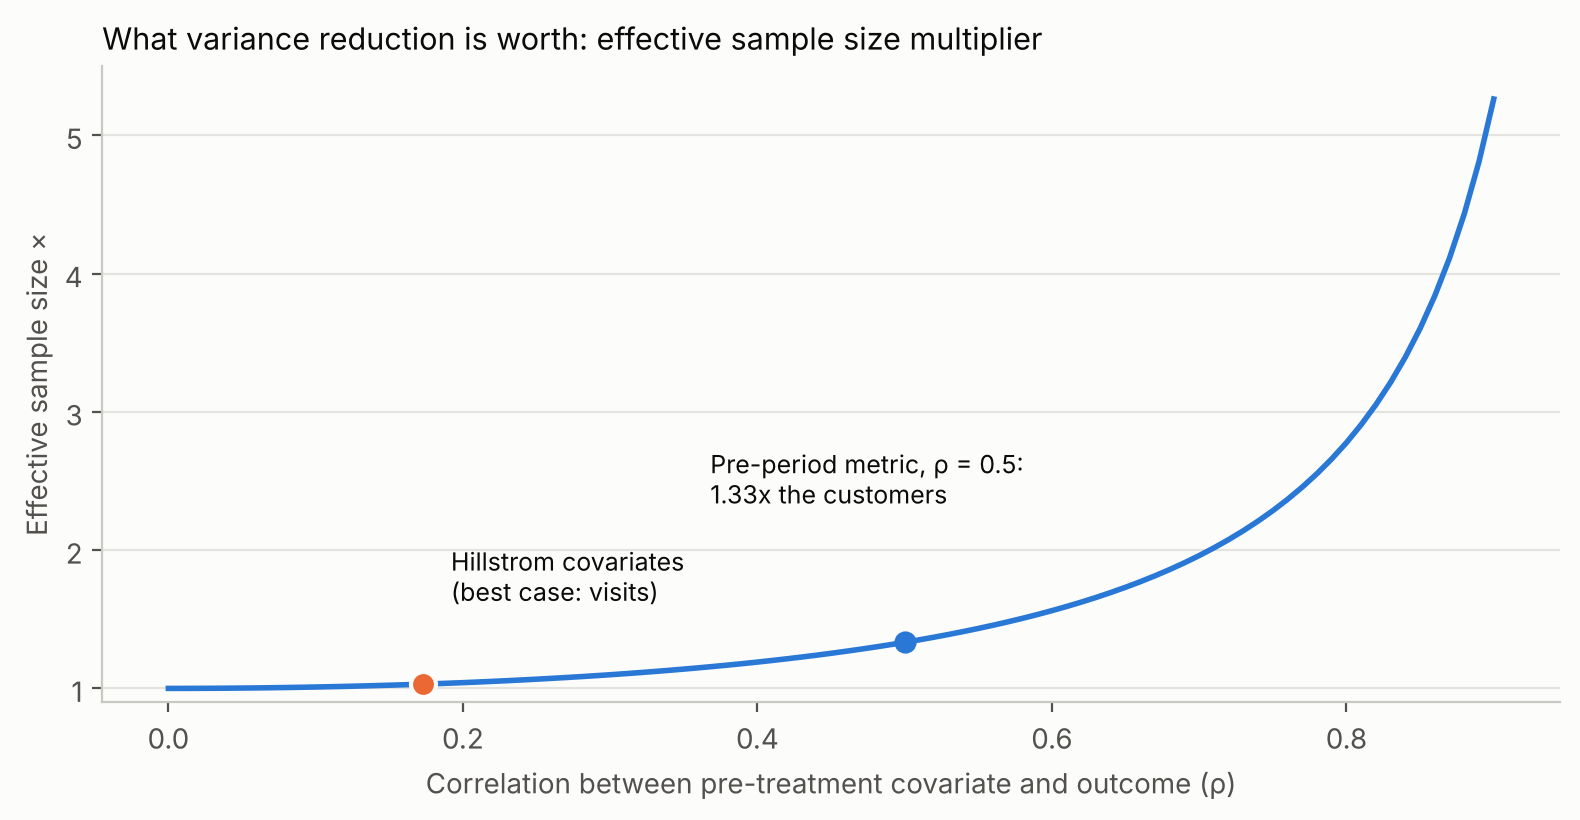

In [5]:
# figure: variance_reduction
rho = np.linspace(0, 0.9, 91)
fig, ax = new_figure(8, 4.2)
ax.plot(rho, 1 / (1 - rho**2), color=SERIES[0], linewidth=2)
hill = np.sqrt(max(r2.values()))
ax.plot(hill, 1 / (1 - hill**2), "o", color=SERIES[1], markersize=9, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
ax.annotate("Hillstrom covariates\n(best case: visits)", (hill, 1 / (1 - hill**2)), xytext=(10, 30),
            textcoords="offset points", color=INK, fontsize=9)
ax.plot(0.5, 1 / (1 - 0.25), "o", color=SERIES[0], markersize=7)
ax.annotate("Pre-period metric, ρ = 0.5:\n1.33x the customers", (0.5, 1 / 0.75), xytext=(-70, 50),
            textcoords="offset points", color=INK, fontsize=9)
style_axes(ax, title="What variance reduction is worth: effective sample size multiplier",
           xlabel="Correlation between pre-treatment covariate and outcome (ρ)", ylabel="Effective sample size ×")
ax.set_ylim(0.9, 5.5)
plt.tight_layout()
plt.show()

## 5. What this means for the business

- **For this test:** nothing changes. The adjusted estimates confirm the results from lessons 03 and 04.
- **For the next test:** recall that the test could not see the break-even lift of +11% (it would have needed about 950,000 customers). A pre-period metric with correlation 0.5 would cut that to about 710,000, and a strong one (0.7) to about 480,000. Combined with a larger test after the catalogue test, that starts to make small effects measurable.
- **The recommendation for the readout:** ask Operations to include each customer's visits and purchases in the comparable period *before* the send in future extracts. It costs nothing and is the cheapest power increase available.

## Try it yourself

**a)** In the simulation, set `true_effect = 0` and count how often each method gives p < 0.05 (use a z-test on the difference). Both should be about 5%. Why does that matter?

**b)** Why must the CUPED covariate be measured *before* the treatment? Describe what goes wrong if you use visits during the test window as the covariate for purchases.

**c)** Using `expt.power.sample_size_proportions`, compute how many customers per group the break-even lift needs, then divide by 1 / (1 - ρ²) for ρ = 0.5 and 0.7. Check the numbers in section 5.